# Traffic Vehicle Detection on Dhaka-AI with YOLO26

Detect and classify 21 kinds of vehicles (cars, buses, rickshaws, CNG auto-rickshaws, human haulers, ...) in crowded Dhaka street images. A YOLO26-s model pretrained on COCO is fine-tuned on the Dhaka-AI 2020 dataset and compared with a YOLOv8-s baseline trained with the same settings, and with published YOLOv5–v8 results on the same dataset. Rare vehicle classes are oversampled during training.

| | |
|---|---|
| **Data** | Dhaka-AI 2020, 3,002 labelled images (1 broken file skipped), 24,368 boxes, 2,551 train / 451 validation |
| **Models** | YOLOv8-s and YOLO26-s, COCO-pretrained, fine-tuned for 50 epochs at 640 px on an RTX 4050 (6 GB) |
| **Rare classes** | stratified split on the rarest class + repeat-factor oversampling (2,551 → 3,430 training images) |
| **Best model** | YOLO26-s + oversampling: mAP@50 **0.559**, mAP@50-95 **0.396** |
| **Controlled baseline** | YOLOv8-s, same settings: 0.538, 0.386 |
| **Published (Saha et al. 2024)** | YOLOv8 on Dhaka-AI: 0.435, 0.276 |

## 1. Setup

### Imports

In [1]:
import os
import random
import shutil
import xml.etree.ElementTree as ET
from pathlib import Path

os.environ["YOLO_VERBOSE"] = "False"     # keep the notebook output short

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

import torch
from ultralytics import YOLO

### Configuration

All experiment settings in one place. `DATASET_DIR` should point to the folder that contains the Dhaka-AI training images and their `.xml` annotation files.

In [2]:
# Set this to the local path containing the dataset.
DATASET_DIR = Path("../dhaka_data/Final Train Dataset")

WORK_DIR = Path("work")                  # converted dataset + training runs (not committed)
YOLO_DATA_DIR = WORK_DIR / "dhaka_yolo"
RUNS_DIR = (WORK_DIR / "runs").resolve()

SEED = 42
VAL_FRACTION = 0.15      # 15% of the labelled images are kept for validation
MAX_IMAGE_SIDE = 1280    # originals go up to 4096 px; smaller copies make training faster
IMAGE_SIZE = 640         # YOLO input size
BATCH_SIZE = 16
EPOCHS = 50
PATIENCE = 15            # early stopping

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Device :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")
print("Epochs :", EPOCHS)

Device : NVIDIA GeForce RTX 4050 Laptop GPU
Epochs : 50


### Reproducibility

Seeds Python, NumPy and PyTorch with `SEED = 42`. The same seed is passed to Ultralytics for its data loader and augmentations.

In [3]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print("seed:", SEED)

seed: 42


## 2. Data

### Dataset

[Dhaka-AI 2020](https://www.kaggle.com/datasets/rifat963/dhakaai-dhaka-based-traffic-detection-dataset) has 3,953 street images from Dhaka. The 3,003 training images have bounding-box labels in Pascal VOC format: one `.xml` file per image, listing every vehicle as a class name plus a box (`xmin, ymin, xmax, ymax` in pixels). The 950 test images have no public labels, so all evaluation uses a validation split taken from the labelled images.

The 21 classes, from most to least common:

In [4]:
CLASSES = [
    "car", "rickshaw", "bus", "three wheelers (CNG)", "motorbike", "truck", "pickup",
    "minivan", "suv", "van", "bicycle", "auto rickshaw", "human hauler", "wheelbarrow",
    "minibus", "ambulance", "taxi", "army vehicle", "scooter", "policecar", "garbagevan",
]
print(len(CLASSES), "classes")

21 classes


### Reading the annotations

Problems found while checking the raw files, and how each one is handled:

| Problem | Files | Fix |
|---|---|---|
| File called `.xml` that is not XML (it holds YOLO text with unknown class ids) | 1 (`231.xml`) | skipped |
| Image size written as `0 × 0` in the XML | 2 | use the real image size |
| XML size differs from the real image (the image was shrunk after labelling) | 3 | divide coordinates by the XML size, so the relative box positions stay correct |
| Boxes that stick out of the image | a few | clipped to the image border |

In [5]:
def find_image(xml_path):
    # the image has the same name as the xml file, but the extension varies (.jpg, .JPG, .png ...)
    for ext in [".jpg", ".JPG", ".jpeg", ".png", ".PNG"]:
        image_path = xml_path.with_suffix(ext)
        if image_path.exists():
            return image_path
    return None


def read_annotation(xml_path):
    # returns one dict per image, or None if the file is broken
    try:
        root = ET.parse(xml_path).getroot()
    except ET.ParseError:
        return None

    image_path = find_image(xml_path)
    real_width, real_height = Image.open(image_path).size

    width = int(root.find("size/width").text)
    height = int(root.find("size/height").text)
    if width == 0 or height == 0:
        width, height = real_width, real_height

    boxes = []
    for obj in root.findall("object"):
        name = obj.find("name").text.strip()
        box = obj.find("bndbox")
        xmin = max(0, float(box.find("xmin").text))
        ymin = max(0, float(box.find("ymin").text))
        xmax = min(width, float(box.find("xmax").text))
        ymax = min(height, float(box.find("ymax").text))
        if xmax - xmin > 1 and ymax - ymin > 1:
            boxes.append({"class": name, "xmin": xmin, "ymin": ymin, "xmax": xmax, "ymax": ymax})

    return {"image": image_path, "width": width, "height": height, "boxes": boxes}


images = []
for xml_path in sorted(DATASET_DIR.glob("*.xml")):
    annotation = read_annotation(xml_path)
    if annotation is None:
        print("skipped broken file:", xml_path.name)
    else:
        images.append(annotation)

print("images with labels:", len(images))

skipped broken file: 231.xml


images with labels: 3002


### One table with every box

Putting all boxes in a single DataFrame (one row per box) makes the statistics below simple `groupby` calls.

In [6]:
rows = []
for image_id, img in enumerate(images):
    for box in img["boxes"]:
        rows.append({
            "image_id": image_id,
            "class": box["class"],
            # box size relative to the image (0..1)
            "rel_width": (box["xmax"] - box["xmin"]) / img["width"],
            "rel_height": (box["ymax"] - box["ymin"]) / img["height"],
        })
boxes_df = pd.DataFrame(rows)

unknown = set(boxes_df["class"]) - set(CLASSES)
print("total boxes   :", len(boxes_df))
print("unknown names :", unknown if unknown else "none")
boxes_df.head()

total boxes   : 24368
unknown names : none


,image_id,class,rel_width,rel_height
0,0,bus,0.211667,0.51250
1,0,bus,0.097500,0.13875
2,0,bus,0.084167,0.05750
3,0,rickshaw,0.059167,0.15875
4,0,rickshaw,0.042500,0.05625


### Class distribution

The dataset is heavily imbalanced (long-tailed). `car` has about 5,500 boxes, while `policecar` has 32 and `garbagevan` only 3.

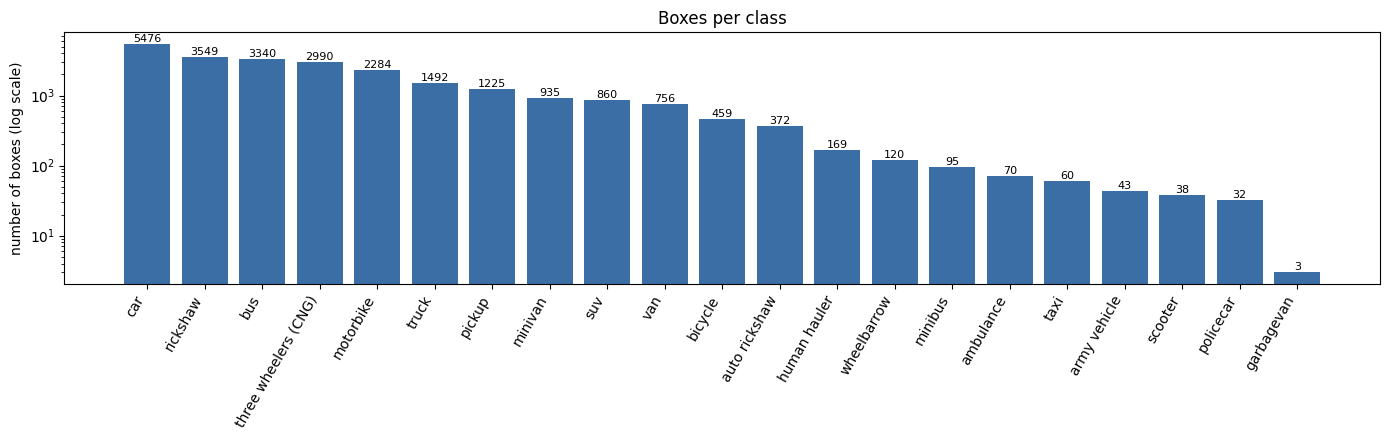

In [7]:
class_counts = boxes_df["class"].value_counts().reindex(CLASSES)

plt.figure(figsize=(14, 4.5))
plt.bar(CLASSES, class_counts.values, color="#3b6ea5")
plt.yscale("log")
plt.ylabel("number of boxes (log scale)")
plt.title("Boxes per class")
plt.xticks(rotation=60, ha="right")
for i, count in enumerate(class_counts.values):
    plt.text(i, count, str(count), ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

### How crowded are the images, and how small are the vehicles?

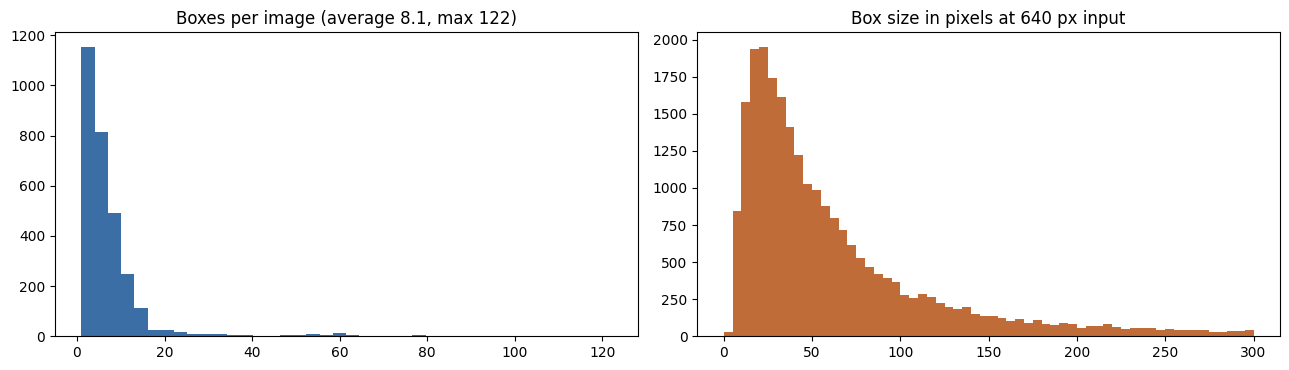

35.7% of boxes are smaller than 32 x 32 px at 640 px input


In [8]:
boxes_per_image = boxes_df.groupby("image_id").size()

# size of a box when the image is resized to 640 px (what YOLO actually sees)
box_size_px = np.sqrt(boxes_df["rel_width"] * boxes_df["rel_height"]) * IMAGE_SIZE

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].hist(boxes_per_image, bins=40, color="#3b6ea5")
ax[0].set_title(f"Boxes per image (average {boxes_per_image.mean():.1f}, max {boxes_per_image.max()})")
ax[1].hist(box_size_px, bins=60, range=(0, 300), color="#c06c39")
ax[1].set_title("Box size in pixels at 640 px input")
plt.tight_layout()
plt.show()

print(f"{(box_size_px < 32).mean():.1%} of boxes are smaller than 32 x 32 px at 640 px input")

### Visual check of a training sample

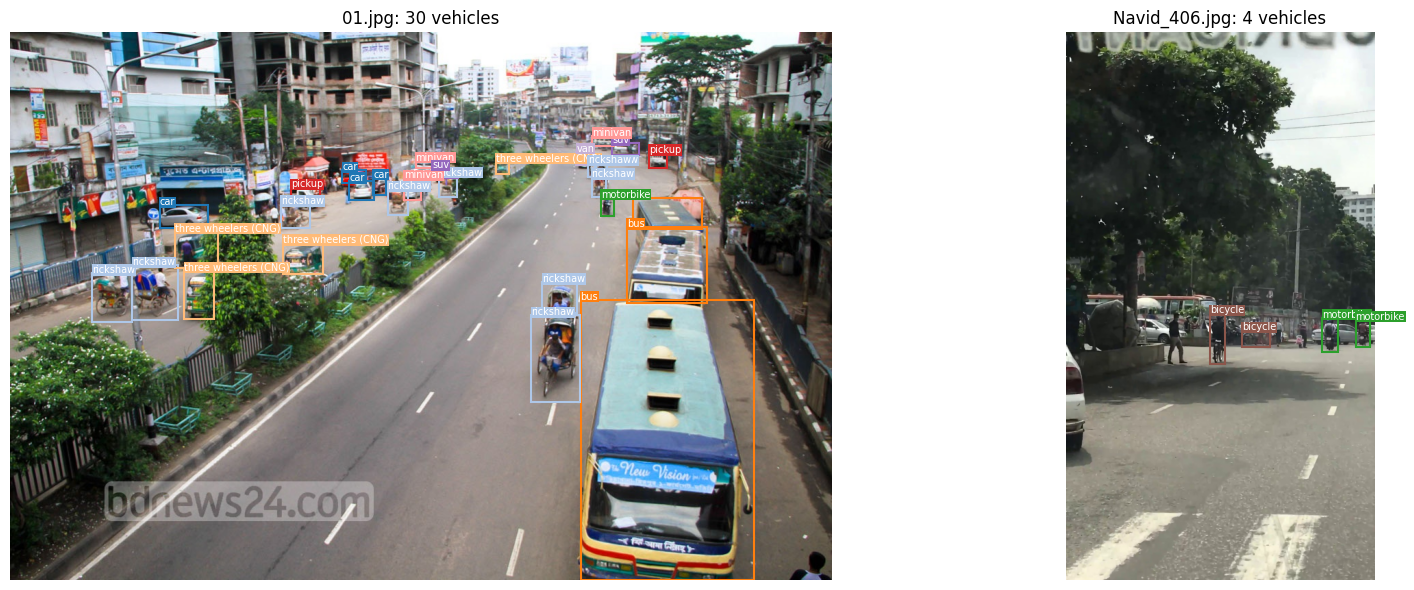

In [9]:
COLORS = plt.cm.tab20(np.linspace(0, 1, len(CLASSES)))


def show_labels(img, ax):
    picture = Image.open(img["image"]).convert("RGB")
    # scale factors in case the image size differs from the xml size
    sx = picture.width / img["width"]
    sy = picture.height / img["height"]
    ax.imshow(picture)
    for box in img["boxes"]:
        color = COLORS[CLASSES.index(box["class"])]
        x, y = box["xmin"] * sx, box["ymin"] * sy
        w, h = (box["xmax"] - box["xmin"]) * sx, (box["ymax"] - box["ymin"]) * sy
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, color=color, linewidth=1.5))
        ax.text(x, y, box["class"], color="white", fontsize=7, bbox=dict(facecolor=color, pad=0.5, linewidth=0))
    ax.set_title(f"{img['image'].name}: {len(img['boxes'])} vehicles")
    ax.axis("off")


fig, ax = plt.subplots(1, 2, figsize=(18, 6))
show_labels(images[0], ax[0])
show_labels(images[1500], ax[1])
plt.tight_layout()
plt.show()

### Train / validation split

A plain random split could put all 3 `garbagevan` boxes in the training set and none in validation. So each image is labelled with the rarest class it contains, and the split is stratified on that label, which puts rare classes in both splits. Seeded 85 / 15 split.

In [10]:
# rarest class in each image
rarest = []
for img in images:
    names = [box["class"] for box in img["boxes"]]
    rarest.append(min(names, key=lambda name: class_counts[name]))

# stratify needs at least 2 images per group, so very small groups are merged
group_sizes = pd.Series(rarest).value_counts()
strata = [name if group_sizes[name] >= 4 else "very rare" for name in rarest]

all_ids = list(range(len(images)))
train_ids, val_ids = train_test_split(all_ids, test_size=VAL_FRACTION, stratify=strata, random_state=SEED)

print("training images   :", len(train_ids))
print("validation images :", len(val_ids))

split_table = pd.DataFrame({
    "train boxes": boxes_df[boxes_df["image_id"].isin(train_ids)]["class"].value_counts(),
    "val boxes": boxes_df[boxes_df["image_id"].isin(val_ids)]["class"].value_counts(),
}).reindex(CLASSES).fillna(0).astype(int)
split_table.T

training images   : 2551
validation images : 451


class,car,rickshaw,bus,three wheelers (CNG),motorbike,truck,pickup,minivan,suv,van,...,auto rickshaw,human hauler,wheelbarrow,minibus,ambulance,taxi,army vehicle,scooter,policecar,garbagevan
train boxes,4729,3077,2868,2557,1965,1259,1033,816,734,641,...,305,151,103,79,59,51,37,33,27,3
val boxes,747,472,472,433,319,233,192,119,126,115,...,67,18,17,16,11,9,6,5,5,0


### Converting to YOLO format

YOLO wants one `.txt` file per image, with one line per box:

```
class_id  x_center  y_center  width  height      (all divided by the image size, so 0..1)
```

Because the numbers are relative, the images can be resized (longest side ≤ 1280 px) without touching the labels. Folder layout expected by Ultralytics:

```
dhaka_yolo/images/train/*.jpg     dhaka_yolo/labels/train/*.txt
dhaka_yolo/images/val/*.jpg       dhaka_yolo/labels/val/*.txt
```

In [11]:
def yolo_line(box, width, height):
    class_id = CLASSES.index(box["class"])
    x_center = (box["xmin"] + box["xmax"]) / 2 / width
    y_center = (box["ymin"] + box["ymax"]) / 2 / height
    box_w = (box["xmax"] - box["xmin"]) / width
    box_h = (box["ymax"] - box["ymin"]) / height
    return f"{class_id} {x_center:.6f} {y_center:.6f} {box_w:.6f} {box_h:.6f}"


def export(ids, split):
    image_dir = YOLO_DATA_DIR / "images" / split
    label_dir = YOLO_DATA_DIR / "labels" / split
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

    for image_id in ids:
        img = images[image_id]
        name = f"img_{image_id:04d}"

        picture = Image.open(img["image"]).convert("RGB")
        picture.thumbnail((MAX_IMAGE_SIDE, MAX_IMAGE_SIDE))   # keeps the aspect ratio
        picture.save(image_dir / f"{name}.jpg", quality=95)

        lines = [yolo_line(box, img["width"], img["height"]) for box in img["boxes"]]
        (label_dir / f"{name}.txt").write_text("\n".join(lines))


export(train_ids, "train")
export(val_ids, "val")

print("example label file:")
print((YOLO_DATA_DIR / "labels" / "train" / f"img_{train_ids[0]:04d}.txt").read_text()[:200])

example label file:
4 0.138281 0.794444 0.143229 0.277778
2 0.438542 0.581944 0.146875 0.302778
2 0.816927 0.597222 0.123438 0.124074
5 0.652604 0.559259 0.201042 0.381481


The dataset description file (`data.yaml`) tells Ultralytics where the images are and what the class names are.

In [12]:
def write_data_yaml(path, train_folder):
    text = f"path: {YOLO_DATA_DIR.resolve()}\n"
    text += f"train: images/{train_folder}\n"
    text += "val: images/val\n"
    text += "names:\n"
    for i, name in enumerate(CLASSES):
        text += f"  {i}: {name}\n"
    path.write_text(text)


DATA_YAML = YOLO_DATA_DIR / "data.yaml"
write_data_yaml(DATA_YAML, "train")
print(DATA_YAML.read_text())

path: /home/varun_001/Desktop/PROJECTS/dhaka-traffic-yolo/work/dhaka_yolo
train: images/train
val: images/val
names:
  0: car
  1: rickshaw
  2: bus
  3: three wheelers (CNG)
  4: motorbike
  5: truck
  6: pickup
  7: minivan
  8: suv
  9: van
  10: bicycle
  11: auto rickshaw
  12: human hauler
  13: wheelbarrow
  14: minibus
  15: ambulance
  16: taxi
  17: army vehicle
  18: scooter
  19: policecar
  20: garbagevan



### Oversampling images with rare vehicles

During normal training the model sees a `car` thousands of times but a `policecar` only about 25 times. A simple fix is to copy training images that contain rare classes, so the model sees them more often (the idea behind *repeat-factor sampling*, Gupta et al., LVIS 2019):

| Rarest class in the image has | Copies of the image |
|---|---|
| fewer than 100 training boxes | 3 |
| 100 – 499 training boxes | 2 |
| 500 or more | 1 (no change) |

Only the training folder changes; validation stays exactly the same, so the results are comparable.

In [13]:
train_counts = split_table["train boxes"]


def copies_for(image_id):
    names = [box["class"] for box in images[image_id]["boxes"]]
    fewest = min(train_counts[name] for name in names)
    if fewest < 100:
        return 3
    if fewest < 500:
        return 2
    return 1


src_images, src_labels = YOLO_DATA_DIR / "images" / "train", YOLO_DATA_DIR / "labels" / "train"
dst_images, dst_labels = YOLO_DATA_DIR / "images" / "train_oversampled", YOLO_DATA_DIR / "labels" / "train_oversampled"
dst_images.mkdir(parents=True, exist_ok=True)
dst_labels.mkdir(parents=True, exist_ok=True)

total = 0
for image_id in train_ids:
    name = f"img_{image_id:04d}"
    for k in range(copies_for(image_id)):
        shutil.copy(src_images / f"{name}.jpg", dst_images / f"{name}_{k}.jpg")
        shutil.copy(src_labels / f"{name}.txt", dst_labels / f"{name}_{k}.txt")
        total += 1

DATA_YAML_OVERSAMPLED = YOLO_DATA_DIR / "data_oversampled.yaml"
write_data_yaml(DATA_YAML_OVERSAMPLED, "train_oversampled")
print(f"training images: {len(train_ids)} -> {total} after oversampling")

training images: 2551 -> 3430 after oversampling


## 3. Training

Three runs with the same settings, so only one thing changes at a time:

| Run | Model | Training images | Question it answers |
|---|---|---|---|
| `yolov8s_baseline` | YOLOv8-s, COCO-pretrained | normal | baseline (same model family as the published results) |
| `yolo26s` | YOLO26-s, COCO-pretrained | normal | does the newer YOLO26 architecture help? |
| `yolo26s_oversampled` | YOLO26-s, COCO-pretrained | oversampled | does oversampling rare classes help? |

Shared settings: 640 px input, batch 16, optimizer and learning rate chosen automatically by Ultralytics, cosine learning-rate schedule, mosaic augmentation (switched off for the last 10 epochs), mixed precision, early stopping with patience 15. The best checkpoint on the validation set is kept.

Fine-tuning means starting from weights already trained on COCO (80 everyday classes, including car, bus, truck, motorcycle and bicycle) instead of random weights, and continuing training on Dhaka-AI with a new 21-class output layer.

In [14]:
def train(run_name, pretrained_weights, data_yaml):
    model = YOLO(pretrained_weights)          # COCO-pretrained starting point
    model.train(
        data=str(data_yaml), epochs=EPOCHS, imgsz=IMAGE_SIZE, batch=BATCH_SIZE,
        patience=PATIENCE, cos_lr=True, close_mosaic=10, seed=SEED,
        device=DEVICE, workers=4, project=str(RUNS_DIR), name=run_name, exist_ok=True,
    )
    return RUNS_DIR / run_name / "weights" / "best.pt"   # checkpoint with the best validation score


best_weights = {}

In [15]:
best_weights["yolov8s_baseline"] = train("yolov8s_baseline", "yolov8s.pt", DATA_YAML)

In [16]:
best_weights["yolo26s"] = train("yolo26s", "yolo26s.pt", DATA_YAML)

In [17]:
best_weights["yolo26s_oversampled"] = train("yolo26s_oversampled", "yolo26s.pt", DATA_YAML_OVERSAMPLED)

### Training curves

Ultralytics writes a `results.csv` per run with the losses and validation metrics of every epoch.

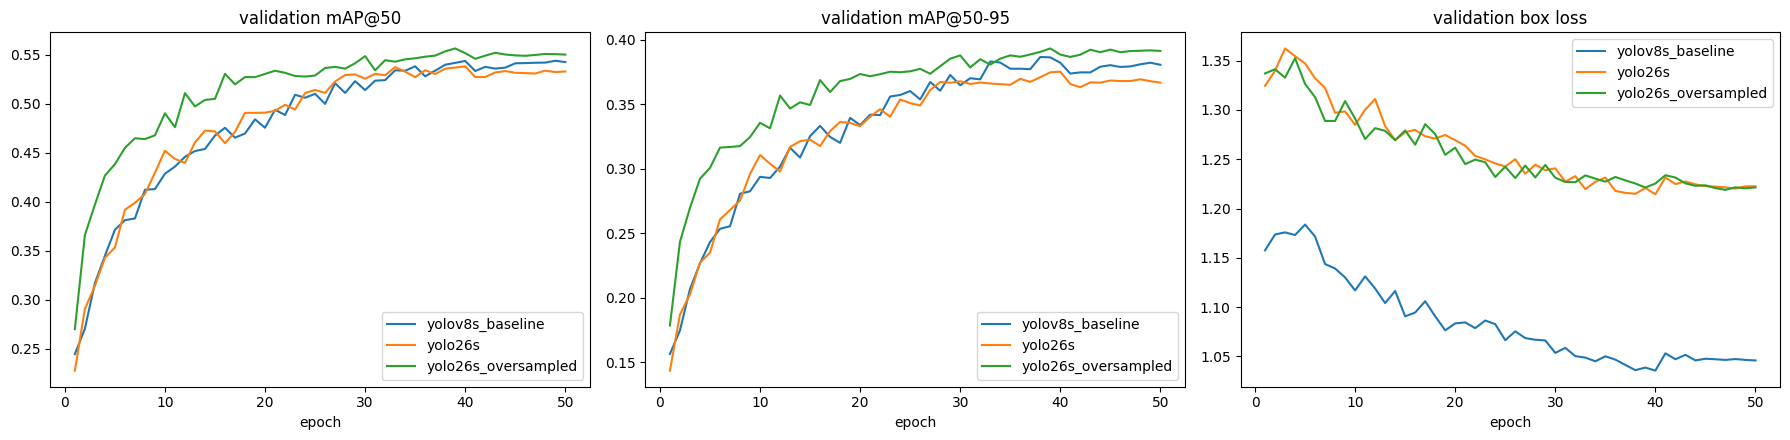

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for run_name in best_weights:
    history = pd.read_csv(RUNS_DIR / run_name / "results.csv")
    history.columns = history.columns.str.strip()
    ax[0].plot(history["epoch"], history["metrics/mAP50(B)"], label=run_name)
    ax[1].plot(history["epoch"], history["metrics/mAP50-95(B)"], label=run_name)
    ax[2].plot(history["epoch"], history["val/box_loss"], label=run_name)

for a, title in zip(ax, ["validation mAP@50", "validation mAP@50-95", "validation box loss"]):
    a.set_title(title)
    a.set_xlabel("epoch")
    a.legend()
plt.tight_layout()
plt.show()

## 4. Evaluation

### Overall metrics on the validation set

- **Precision**: of the boxes the model drew, how many were correct.
- **Recall**: of the real vehicles, how many the model found.
- **mAP@50**: mean Average Precision when a predicted box counts as correct if it overlaps the real box by at least 50% (IoU ≥ 0.5), averaged over all classes.
- **mAP@50-95**: the same, averaged over stricter overlap thresholds 0.50, 0.55, … 0.95, so it also rewards tight boxes. This is the main COCO metric.

In [19]:
val_results = {}
for run_name, weights in best_weights.items():
    model = YOLO(str(weights))
    val_results[run_name] = model.val(
        data=str(DATA_YAML), split="val", imgsz=IMAGE_SIZE, batch=BATCH_SIZE, device=DEVICE,
        project=str(RUNS_DIR), name=f"{run_name}_val", exist_ok=True,
    )

overall_rows = []
for run_name, result in val_results.items():
    overall_rows.append({
        "model": run_name,
        "precision": result.box.mp,
        "recall": result.box.mr,
        "mAP@50": result.box.map50,
        "mAP@50-95": result.box.map,
        "inference ms / image": result.speed["inference"],
    })
overall = pd.DataFrame(overall_rows).set_index("model").round(3)
overall

,precision,recall,mAP@50,mAP@50-95,inference ms / image
model,,,,,
yolov8s_baseline,0.704,0.502,0.538,0.386,5.281
yolo26s,0.721,0.473,0.536,0.376,5.633
yolo26s_oversampled,0.647,0.542,0.559,0.396,5.340


### Class-wise results

AP@50 for every class and every model, next to the number of training boxes. Rare classes are at the bottom of the table.

In [20]:
per_class = split_table.copy()
for run_name, result in val_results.items():
    ap50_by_class = dict(zip(result.box.ap_class_index, result.box.ap50))
    per_class[f"{run_name} AP50"] = [ap50_by_class.get(i, np.nan) for i in range(len(CLASSES))]
per_class = per_class.round(3)
per_class

,train boxes,val boxes,yolov8s_baseline AP50,yolo26s AP50,yolo26s_oversampled AP50
class,,,,,
car,4729,747,0.760,0.775,0.775
rickshaw,3077,472,0.739,0.743,0.768
bus,2868,472,0.787,0.826,0.836
three wheelers (CNG),2557,433,0.795,0.805,0.806
motorbike,1965,319,0.676,0.728,0.732
truck,1259,233,0.739,0.753,0.764
pickup,1033,192,0.533,0.524,0.545
minivan,816,119,0.469,0.516,0.477
suv,734,126,0.436,0.455,0.499


In [21]:
is_rare = per_class["train boxes"] < 150
ap_columns = [f"{run_name} AP50" for run_name in best_weights]

rare_vs_common = pd.DataFrame({
    "common classes (>= 150 train boxes)": per_class.loc[~is_rare, ap_columns].mean(),
    "rare classes (< 150 train boxes)": per_class.loc[is_rare, ap_columns].mean(),
}).round(3)
print("rare classes:", list(per_class.index[is_rare]))
rare_vs_common

rare classes: ['wheelbarrow', 'minibus', 'ambulance', 'taxi', 'army vehicle', 'scooter', 'policecar', 'garbagevan']


,common classes (>= 150 train boxes),rare classes (< 150 train boxes)
yolov8s_baseline AP50,0.619,0.388
yolo26s AP50,0.637,0.348
yolo26s_oversampled AP50,0.646,0.396


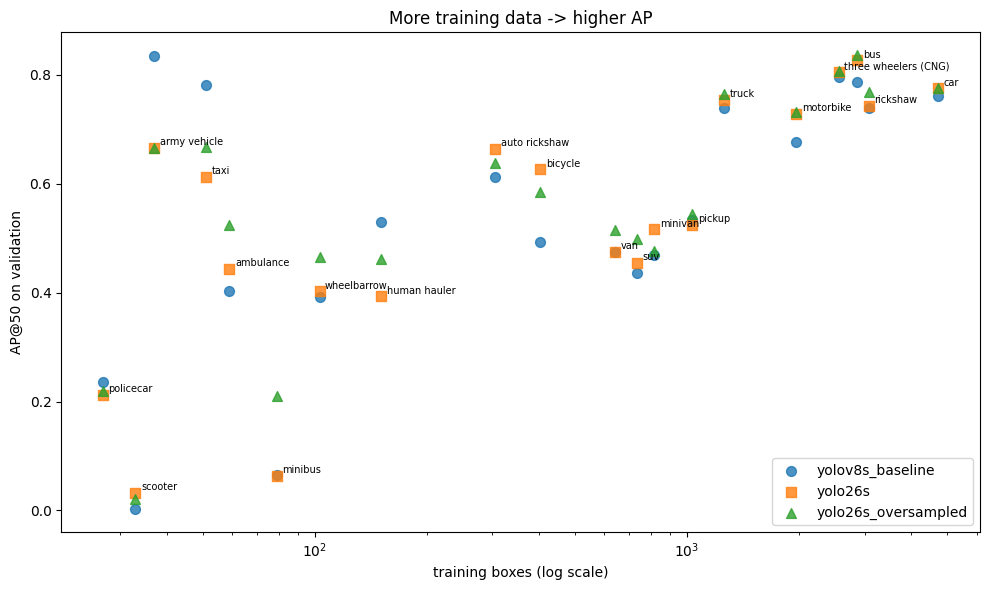

In [22]:
plt.figure(figsize=(10, 6))
for run_name, marker in zip(best_weights, ["o", "s", "^"]):
    plt.scatter(per_class["train boxes"], per_class[f"{run_name} AP50"], label=run_name, marker=marker, s=50, alpha=0.8)
for class_name, row in per_class.iterrows():
    plt.annotate(class_name, (row["train boxes"], row["yolo26s AP50"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
plt.xscale("log")
plt.xlabel("training boxes (log scale)")
plt.ylabel("AP@50 on validation")
plt.title("More training data -> higher AP")
plt.legend()
plt.tight_layout()
plt.show()

### Confusion matrix of the best model

Each column is a true class, each row the predicted class, normalised per true class. The `background` row counts vehicles the model missed; the `background` column counts boxes it drew where there was no vehicle.

best model: yolo26s_oversampled


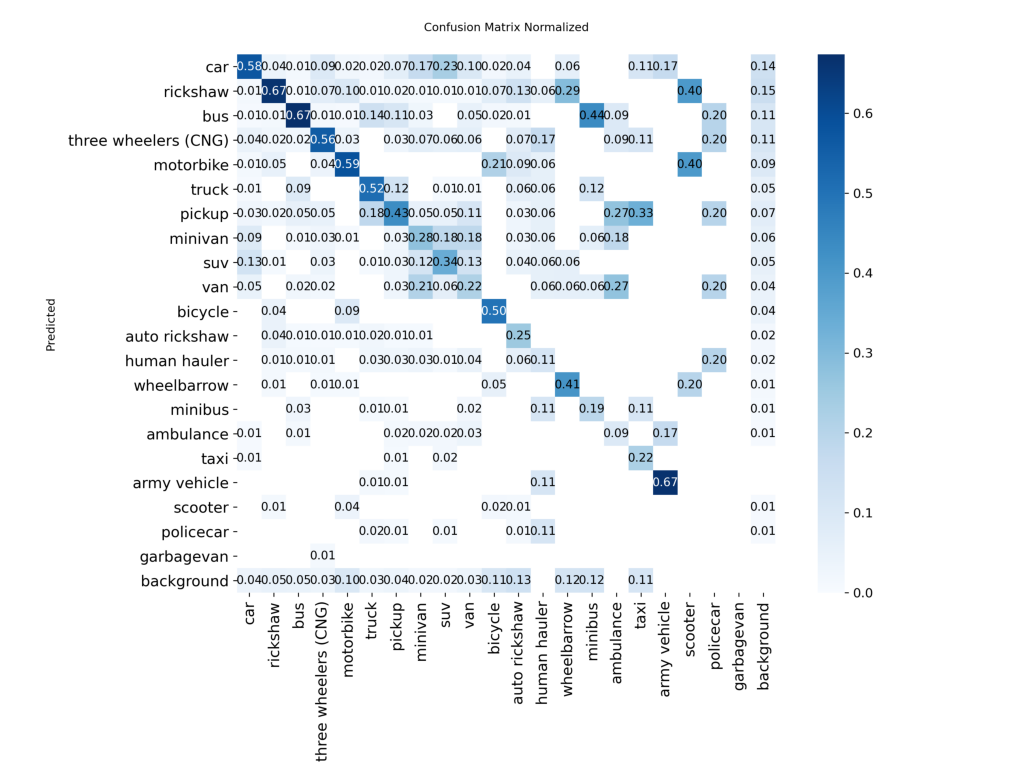

In [23]:
best_run = overall["mAP@50-95"].idxmax()
print("best model:", best_run)

plt.figure(figsize=(13, 11))
plt.imshow(Image.open(RUNS_DIR / f"{best_run}_val" / "confusion_matrix_normalized.png"))
plt.axis("off")
plt.show()

### Predictions on validation images

Left: the human labels. Right: the predictions of the best model (confidence ≥ 0.25).

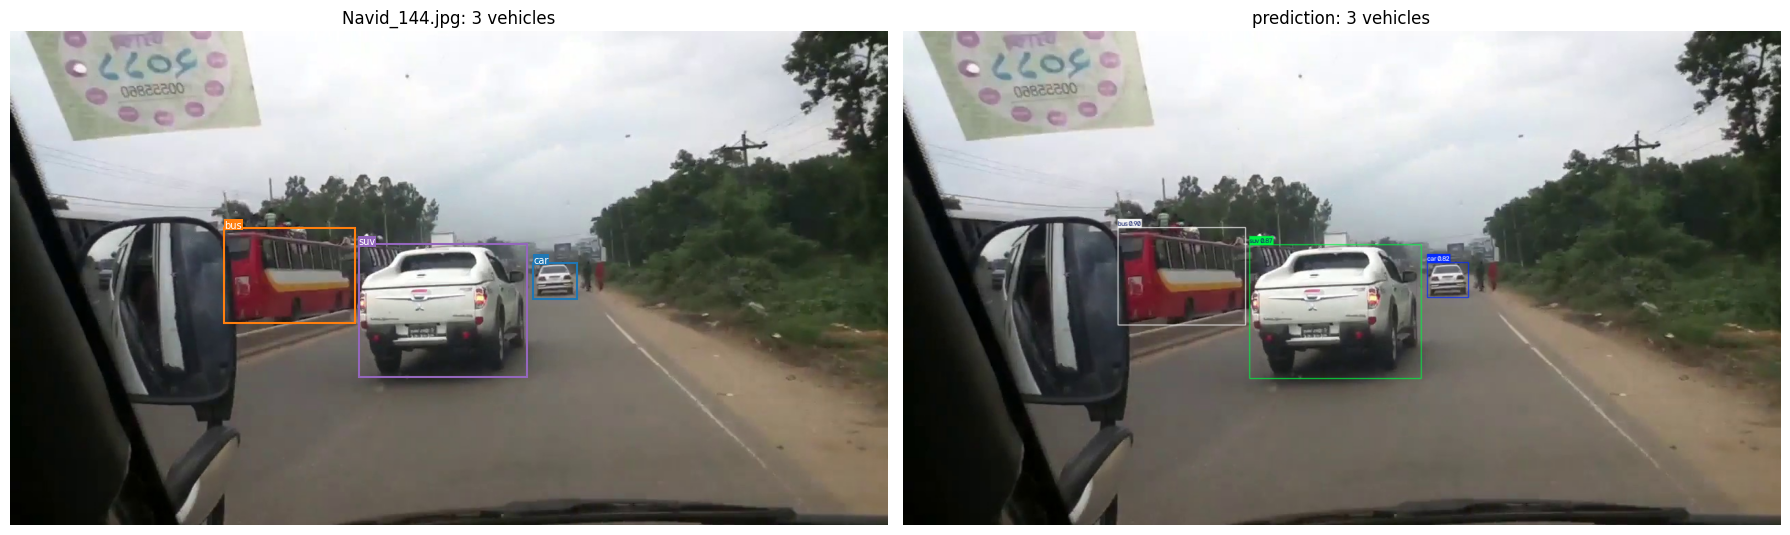

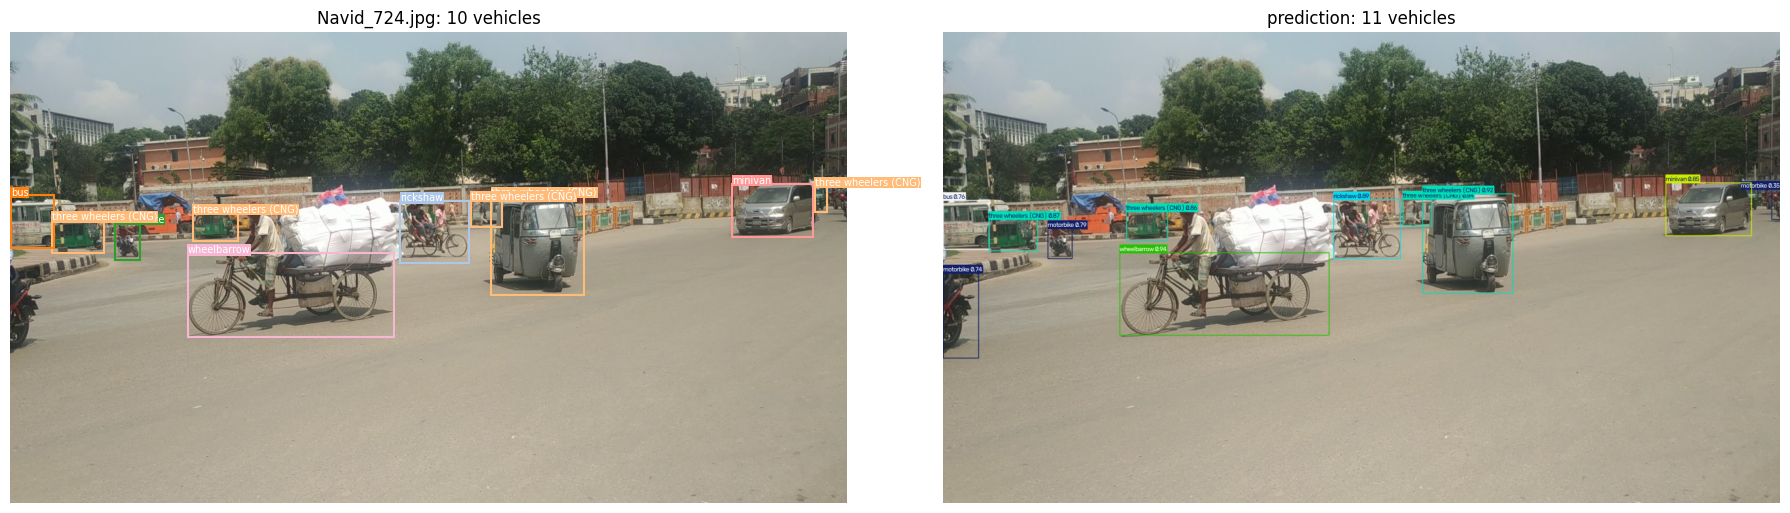

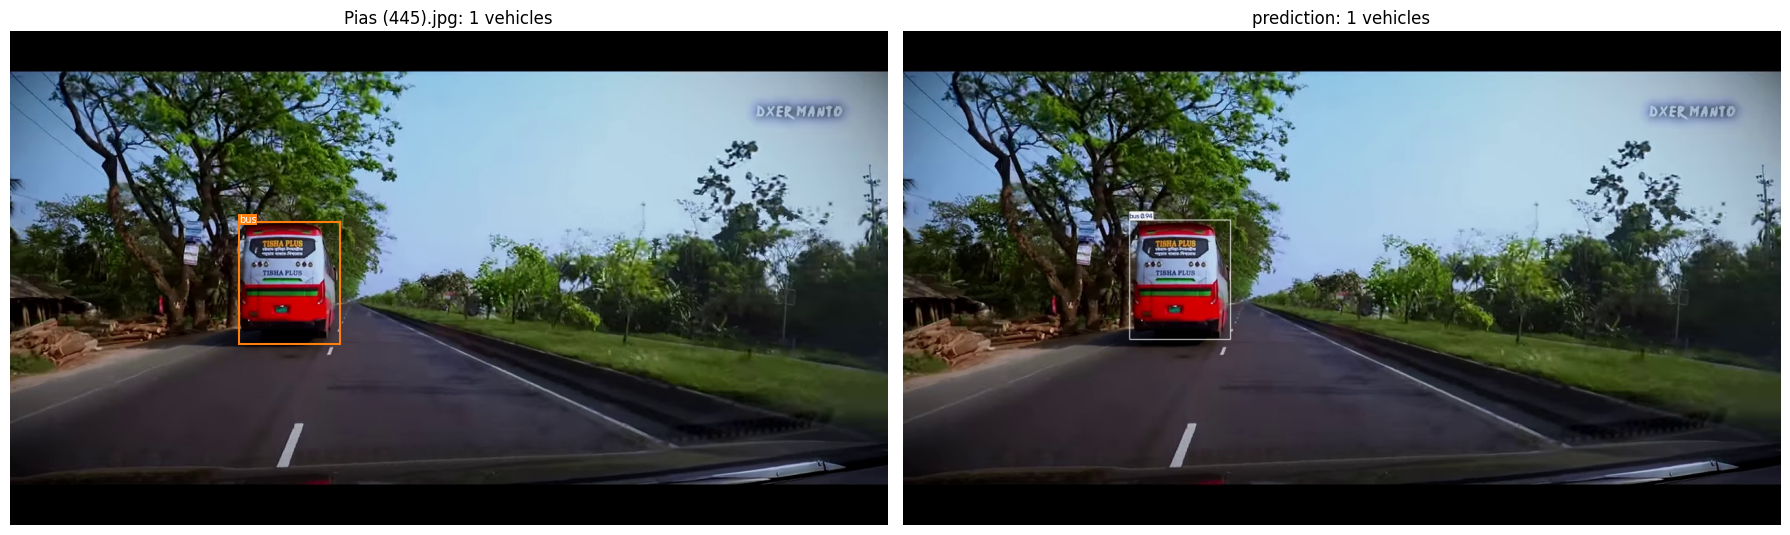

In [24]:
best_model = YOLO(str(best_weights[best_run]))
examples = random.Random(SEED).sample(list(val_ids), 3)

for image_id in examples:
    prediction = best_model.predict(str(YOLO_DATA_DIR / "images" / "val" / f"img_{image_id:04d}.jpg"),
                                    imgsz=IMAGE_SIZE, conf=0.25, device=DEVICE)[0]
    fig, ax = plt.subplots(1, 2, figsize=(18, 6))
    show_labels(images[image_id], ax[0])
    ax[1].imshow(prediction.plot(line_width=1, font_size=8)[:, :, ::-1])   # BGR -> RGB
    ax[1].set_title(f"prediction: {len(prediction.boxes)} vehicles")
    ax[1].axis("off")
    plt.tight_layout()
    plt.show()

## 5. Comparison with published results

Saha et al. (2024), *Bangladeshi Native Vehicle Detection in Wild*, arXiv:2405.12150, Table VII, trained YOLOv5–v8 on Dhaka-AI. Their split and training settings are not identical to ours, so this comparison is indicative; the YOLOv8-s baseline in this notebook is the controlled comparison.

In [25]:
published = pd.DataFrame({
    "mAP@50": [0.416, 0.420, 0.464, 0.435],
    "mAP@50-95": [0.255, 0.262, 0.284, 0.276],
}, index=["YOLOv5 (Saha et al. 2024)", "YOLOv6 (Saha et al. 2024)",
          "YOLOv7 (Saha et al. 2024)", "YOLOv8 (Saha et al. 2024)"])

ours = overall[["mAP@50", "mAP@50-95"]].copy()
ours.index = [f"{name} (this notebook)" for name in ours.index]

comparison = pd.concat([published, ours]).round(3)
comparison

,mAP@50,mAP@50-95
YOLOv5 (Saha et al. 2024),0.416,0.255
YOLOv6 (Saha et al. 2024),0.420,0.262
YOLOv7 (Saha et al. 2024),0.464,0.284
YOLOv8 (Saha et al. 2024),0.435,0.276
yolov8s_baseline (this notebook),0.538,0.386
yolo26s (this notebook),0.536,0.376
yolo26s_oversampled (this notebook),0.559,0.396


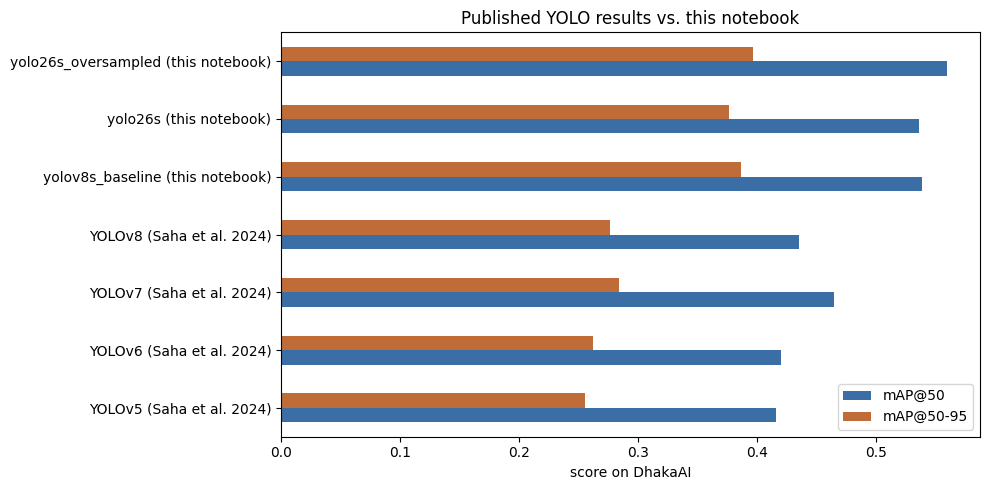

In [26]:
comparison.plot.barh(figsize=(10, 5), color=["#3b6ea5", "#c06c39"])
plt.xlabel("score on DhakaAI")
plt.title("Published YOLO results vs. this notebook")
plt.tight_layout()
plt.show()

## Results

### Overall (validation split, 451 images)

| Model | Precision | Recall | mAP@50 | mAP@50-95 | Inference (ms/img, RTX 4050) |
|---|---:|---:|---:|---:|---:|
| YOLOv8-s baseline | 0.704 | 0.502 | 0.538 | 0.386 | 5.3 |
| YOLO26-s | **0.721** | 0.473 | 0.536 | 0.376 | 5.6 |
| **YOLO26-s + oversampling** | 0.647 | **0.542** | **0.559** | **0.396** | 5.3 |

### Rare vs. common classes (mean AP@50)

| Model | Common classes (≥ 150 train boxes) | Rare classes (< 150 train boxes) |
|---|---:|---:|
| YOLOv8-s baseline | 0.619 | 0.388 |
| YOLO26-s | 0.637 | 0.348 |
| **YOLO26-s + oversampling** | **0.646** | **0.396** |

### Findings

1. All three fine-tuned models score higher than the published Dhaka-AI results (best published: YOLOv7 0.464 mAP@50, YOLOv8 0.435), about 0.10 mAP@50 above the published YOLOv8. The splits and settings differ, so this comparison is indicative.
2. With the same settings, YOLO26-s and YOLOv8-s are about equal overall (mAP@50 0.536 vs 0.538). YOLO26-s is better on the common classes (+0.018 AP@50) and more precise, but weaker on the rare classes (−0.040). Its NMS-free end-to-end inference helps deployment on CPUs and edge devices more than it helps accuracy at this scale.
3. Oversampling rare classes gives the best model: +0.023 mAP@50 and +0.020 mAP@50-95 over plain YOLO26-s, with rare-class AP@50 rising from 0.348 to 0.396. The biggest gains are `minibus` (0.06 → 0.21), `ambulance` (0.44 → 0.52), `human hauler` (0.39 → 0.46) and `wheelbarrow` (0.40 → 0.47). Recall rises from 0.47 to 0.54 and precision drops from 0.72 to 0.65, because the model now predicts the rare classes more often.
4. The confusion matrix shows that most errors are between look-alike classes (car, SUV and minivan; minivan and van; truck, pickup and bus; minibus predicted as bus). Small two-wheelers (scooter, bicycle) are often predicted as `motorbike` or missed.
5. `scooter` (33 training boxes, AP@50 ≈ 0.02) and `policecar` (27, ≈ 0.22) are still unsolved, and `garbagevan` (3 boxes, all in training) cannot be evaluated. These classes need more labelled data.

### Limitations

Evaluation uses a held-out validation split because the official test labels are not public. Rare classes have only 5–17 validation boxes each, so their per-class AP is noisy. Each model was trained once (seed 42) without hyper-parameter search.